# Determinacy in the sequence space

Whether a model has a unique bounded solution, read off its sequence-space Jacobian.

Implements the winding number criterion of Auclert, Majic, Rognlie and Straub (2025),
*Determinacy and Large-Scale Solutions in the Sequence Space*.

In [1]:
import warnings

import numpy as np
import matplotlib.pyplot as plt

import sequence_jacobian as sj
from sequence_jacobian import SteadyStateDict, grids
from sequence_jacobian.examples import hank, krusell_smith

## The symbol

`H_U`, the Jacobian of targets with respect to unknowns, is a convolution: constant
along diagonals. Its **symbol** collects those diagonals into a function on the unit
circle,

$$ j(z) = \sum_k j_k z^k, $$

and geometric sequences are its eigenvectors: feed in $x_s = z^{-s}$ and the same
sequence comes back scaled by $j(z)$. The symbol is the model's transfer function, and
$j(1)$ is the cumulative response to a permanent change.

Determinacy then reduces to whether $\det j(z)$ winds around the origin. The two
simplest cases are the lag and lead operators.

In [2]:
@sj.simple
def lag(u):
    resid = u(-1)
    return resid

@sj.simple
def lead(u):
    resid = u(+1)
    return resid

ss = SteadyStateDict({'u': 1.0, 'resid': 1.0})

for block in (lag, lead):
    model = sj.create_model([block], name=f'{block.name}_model')
    print(f'{block.name:5s}',
          repr(model.winding_number(ss, ['u'], ['resid'], T=20, n_sample=512)))

lag   1  (no bounded solution for generic shocks (nonexistence of dimension 1))
lead  -1  (indeterminate: bounded solutions form a 1-dimensional family)


`L` maps $(x_0, x_1, \dots) \mapsto (0, x_0, \dots)$: injective, but nothing with a
non-zero first entry lies in its range, so $Lx = y$ usually has no solution. `F` drops
the first entry, so its kernel is one-dimensional and solutions are never unique.

The value returned is an ordinary `int` that explains itself when echoed.

## The Taylor principle

On the one-asset HANK model shipped with the package.

In [3]:
_, ss_hank, hank_model, unknowns, targets, _ = hank.dag()
ss_hank = ss_hank.copy()

for phi in [0.0, 0.5, 0.9, 1.01, 1.5, 2.5]:
    ss_hank['phi'] = phi
    wind = hank_model.winding_number(ss_hank, unknowns, targets, T=200, n_sample=2048)
    print(f'phi = {phi:4.2f}   {wind!r}')

phi = 0.00   -1  (indeterminate: bounded solutions form a 1-dimensional family)
phi = 0.50   -1  (indeterminate: bounded solutions form a 1-dimensional family)
phi = 0.90   -1  (indeterminate: bounded solutions form a 1-dimensional family)
phi = 1.01   0  (unique bounded solution)


phi = 1.50   0  (unique bounded solution)
phi = 2.50   0  (unique bounded solution)


C:\Users\A2610226\Projects\sequence-jacobian\src\sequence_jacobian\blocks\block.py:363: UserWarning: det j(z) comes within 3.3e-03 of the origin relative to its largest value, so the winding number is not a reliable verdict: the criterion assumes no zero on the unit circle, and this model is close to having one. The closest approach is at z = -1, so the near-root alternates with period two.


The boundary sits exactly at $\phi = 1$.

## Looking at the path

The integer summarises a curve. `return_path=True` also returns $\det j(z)$ itself,
traced counterclockwise around the unit circle. Whether it encircles the origin *is* the
verdict; how close it passes says how much to trust it.

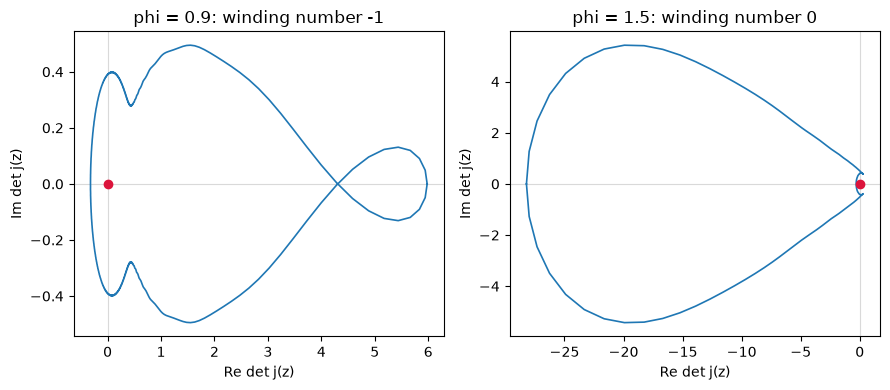

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(9, 4))

for ax, phi in zip(axes, [0.9, 1.5]):
    ss_hank['phi'] = phi
    wind, path = hank_model.winding_number(ss_hank, unknowns, targets, T=200,
                                           n_sample=2048, return_path=True)
    closed = np.append(path, path[0])
    ax.plot(closed.real, closed.imag, lw=1.2)
    ax.plot(0, 0, 'o', color='crimson', ms=6)
    ax.axhline(0, color='0.85', lw=0.8, zorder=0)
    ax.axvline(0, color='0.85', lw=0.8, zorder=0)
    ax.set_title(f'phi = {phi}: winding number {int(wind)}')
    ax.set_xlabel('Re det j(z)')
    ax.set_ylabel('Im det j(z)')

fig.tight_layout()

At $\phi = 0.9$ the curve wraps once around the origin; at $\phi = 1.5$ it stays clear.

## Cyclical income risk

Determinacy is not only about the policy rule. Making idiosyncratic income risk depend on
aggregate activity is a few lines, via a hetinput that rebuilds the income grid: here the
cross-sectional dispersion of labour income falls with aggregate labour when
$\omega > 0$, so risk is countercyclical.

Aggregate labour is one in steady state, so the steady state is untouched and only the
dynamics change.

In [5]:
def make_grids_cyclical(rho_s, sigma_s, nS, amax, nA, L, omega):
    sigma = sigma_s * L ** (-omega)
    e_grid, pi_e, Pi = grids.markov_rouwenhorst(rho=rho_s, sigma=sigma, N=nS)
    a_grid = grids.agrid(amax=amax, n=nA)
    return e_grid, pi_e, Pi, a_grid

household = hank.hh.add_hetinputs([hank.transfers, hank.wages, make_grids_cyclical])
household = household.add_hetoutputs([hank.labor_supply])
cyclical = sj.create_model(
    [household, hank.firm, hank.monetary, hank.fiscal, hank.mkt_clearing, hank.nkpc],
    name='HANK with cyclical risk')

ss_cyc = ss_hank.copy()
ss_cyc['phi'] = 1.5          # a policy rule that is determinate on its own

closeness = []
for omega in [0.0, 1.0, 2.0, 4.0, 8.0]:
    ss_cyc['omega'] = omega
    with warnings.catch_warnings():
        warnings.simplefilter('ignore')
        wind, path = cyclical.winding_number(ss_cyc, unknowns, targets, T=200,
                                             n_sample=2048, return_path=True)
    m = np.abs(path)
    closeness.append(m.min() / m.max())
    print(f'omega = {omega:4.1f}   {wind!r}\n             min|det|/max = {m.min() / m.max():.2e}')

omega =  0.0   0  (unique bounded solution)
             min|det|/max = 1.08e-02
omega =  1.0   0  (unique bounded solution)
             min|det|/max = 9.39e-03
omega =  2.0   0  (unique bounded solution)
             min|det|/max = 7.90e-03


omega =  4.0   0  (unique bounded solution)
             min|det|/max = 4.55e-03
omega =  8.0   1  (no bounded solution for generic shocks (nonexistence of dimension 1))
             min|det|/max = 2.26e-03


Raising $\omega$ walks the determinant steadily towards the origin, and past some point
the verdict changes: a rule that is determinate with acyclical risk need not be with
countercyclical risk. The paper finds the same mechanism matters, and locates a precise
threshold in its own model; the sign of the flip here is not directly comparable, since
this is a different model and a different parameterisation of cyclicality.

Note that `winding_number` warns once the path comes near the origin, which it does here
well before the flip. Those warnings are suppressed above only to keep the table readable
-- they are the point.

## When zero is not enough

Take the null hypothesis to be that the model has a unique bounded solution. A non-zero
winding number rejects it decisively. Zero fails to reject, but only *generically*, so it
can be a false positive.

That case is not exotic. For the intertemporal Keynesian cross in goods space, $I - M$,
the household present-value budget constraint forces $q'(I - M) = 0$ with
$q = (1, (1+r)^{-1}, \dots)$, so the range holds only sequences of zero net present
value. Not invertible -- yet the winding number is zero. Economic structure imposes exact
restrictions that a randomly perturbed operator would never satisfy, so genericity in the
space of operators does not carry over to the space of models. Suspect adding-up
constraints and conservation laws.

Non-genericity always produces nonexistence *and* indeterminacy together, so ruling out
nonexistence rules out both. `check_existence` does that: feed in random decaying
sequences, solve the truncated system, and watch how the answer scales with the horizon.
Nothing converges when no solution exists.

In [6]:
_, ss_ks, ks_model, ks_unknowns, ks_targets, _ = krusell_smith.dag()

growth = ks_model.check_existence(ss_ks, ks_unknowns, ks_targets,
                                  T=100, T_compare=200, n_draws=20)
print(f'Krusell-Smith: the solution grows by {growth:.3f}x when T doubles')

Krusell-Smith: the solution grows by 1.000x when T doubles


A genuine solution barely moves. Contrast the lag operator, whose truncation is
outright singular:

In [7]:
lag_model = sj.create_model([lag], name='lag_model')

with warnings.catch_warnings(record=True) as caught:
    warnings.simplefilter('always')
    growth = lag_model.check_existence(ss, ['u'], ['resid'], T=20, T_compare=40,
                                       n_draws=5)
print('growth:', growth)
print('warned:', caught[0].message)

growth: inf
warned: The truncated system is exactly singular, so H_U x = y has no solution for generic y.


## Notes

Two assumptions cannot be verified numerically, only probed, so `winding_number` warns
about them:

- **No zero of $\det j(z)$ on the unit circle.** Where $\det j(z_0) = 0$ the sequence
  $z_0^{-s}$ is annihilated by `H_U`; having modulus one it neither decays nor explodes,
  so it is a bounded solution of the homogeneous system and the model sits at a knife
  edge. Where on the circle diagnoses which kind: $z_0 = 1$ is a unit root, $z_0 = -1$
  alternates, a complex $z_0$ is a deterministic cycle.
- **Enough samples.** The count is exact only if the argument moves by less than $\pi$
  between neighbours. Raise `n_sample` if warned.

Solved blocks are unwrapped and their unknowns promoted automatically, since solving
inside a block inverts an operator that the symbol cannot see through.

`fake_news_matrix` exposes the intermediate the symbol of a heterogeneous-agent block is
built from, which is of interest in its own right.